# A4 · Mask2Former (Swin) **agnóstico** (Propuesta 1: segmentador)

Afina Mask2Former (Hugging Face, backbone Swin) con **una sola clase («food»)**: solo aprende *dónde* hay comida y con qué máscara.

**Requisitos:** GPU y, en Colab, Google Drive montado (los datos se descargan solos desde Drive; ver abajo). A diferencia de RTMDet-Ins, no depende de MMCV: solo `transformers` (ya viene en Colab).

**Cómo se alimenta (todo desde tu Google Drive):**

| Archivo en Drive | Para qué |
|---|---|
| `food-recognition-2022.zip` | Imágenes originales (el 00 no las incluye) |
| `food-prep-v21.zip` | Salida del 00: `classes.json`, `splits.json`, `coco_*.json`, `manifest.json` (las carpetas de recortes se omiten al extraer: este cuadernillo no las usa) |
| `food_utils_v3.py` (o `_v2`) | Utilidades comunes (se copia como `food_utils.py`); si hay varias versiones en Drive se elige la más completa |

Los archivos se **buscan por nombre** en tu Drive (`calorie_counter` y `MyDrive`, hasta 3 niveles) y, si no están, se intentan bajar con `gdown`. Se extraen en el disco local de Colab (`/content/data`); los **pesos, el historial y los resultados** se guardan en Drive.

**Qué hace**
1. Prepara los datos (busca, extrae y valida) y carga `food_utils.Prep`, excluyendo las fotos con geometría irreconciliable.
2. Carga `facebook/mask2former-swin-*-coco-instance` (pesos COCO) y reinicia la cabeza de clases (`ignore_mismatched_sizes`).
3. Entrena con **mi propio bucle** (letterbox a `imgsz`, volteo, AdamW con LR del backbone ×0.1, calentamiento + coseno). La pérdida (emparejamiento húngaro + máscaras) la calcula el propio modelo al recibir `mask_labels`/`class_labels`. Cada época evalúa la **validación** (AP agnóstico), guarda `best.pt` y, tras cada época, `last.pt` (+ copia `last_prev.pt`) e `history.csv` en Drive para **reanudar** tras una desconexión.
4. Predice con la **inferencia de instancias oficial de Mask2Former** (top-100 pares consulta×clase, puntuación = probabilidad de clase × calidad de la máscara), la llevo a la foto original y guarda predicciones COCO (RLE). Se evalúa **solo** en modo agnóstico.
5. Mide parámetros, latencia y memoria y escribe `resultados/A4_*.json`.

> **Modo piloto (`pilot=True`, por defecto).** 1 época con el 5 % de los datos y 50 imágenes por split: comprueba que todo el flujo funciona y estima el tiempo por época. Escribe en `resultados_pilot/`.

> **Espacio en Drive y progreso.** `best.pt` pesa ~0.2 GB y `last.pt` (modelo + optimizador) ~0.6 GB. `last.pt` se guarda **en cada época** (`ckpt_every=1`) con escritura atómica y se conserva una copia de seguridad (`last_prev.pt`, `keep_prev_ckpt=True`); ambos **se conservan al terminar** (`cleanup_last=False`) por si quieres seguir entrenando más épocas; ponlo en `True` para liberar ~1.2 GB (el historial queda siempre en `history.csv`). Necesitas unos **3 GB libres** en Drive.

> **Referencia de evaluación.** Se evalúa contra las máscaras **originales** de COCO (`coco_*.json`), igual que A1–A3/B1–B3. El refinamiento con SAM 2 del cuadernillo 00 solo afecta a los recortes de los clasificadores (familia C).

> **Equidad.** Parte de pesos COCO (como los demás). Los hiperparámetros salen de la receta oficial adaptada a ajuste fino, **no están afinados para este dataset**. Mask2Former emite varias hipótesis de clase por máscara (top-100), igual que la evaluación estándar de COCO.

> **Precisión numérica.** `amp="auto"` usa bfloat16 si la GPU lo soporta (A100/L4) y **desactiva** AMP en una T4 (fp16 es menos estable con esta pérdida). Si ves pérdidas NaN, pon `amp="off"`. La latencia se anota con la precisión usada.

In [1]:
import os, sys, re, json, time, glob, random, shutil, subprocess, importlib
from pathlib import Path
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # menos fragmentación de VRAM (debe fijarse antes de importar torch)
import numpy as np

def ensure(pkg):
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for p in ("transformers", "scipy", "pycocotools", "gdown"): ensure(p)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/calorie_counter")          # persiste entre sesiones (pesos, resultados)
    DATA = Path("/content/data")                                    # disco local: zips extraídos
elif Path("/kaggle/working").exists():
    WORK, DATA = Path("/kaggle/working/calorie_counter"), Path("/kaggle/working/data")
else:
    WORK, DATA = Path("./calorie_counter"), Path("./data")
WORK.mkdir(parents=True, exist_ok=True); DATA.mkdir(parents=True, exist_ok=True)
print("WORK (persistente):", WORK, "| DATA (local):", DATA)

Mounted at /content/drive
WORK (persistente): /content/drive/MyDrive/calorie_counter | DATA (local): /content/data


## 0. Datos desde Drive

Busca los tres archivos, extrae los dos zips en `DATA` (se omite si ya están extraídos en esta sesión) y localiza las carpetas que necesita `food_utils`. Si algún archivo tiene otro nombre o está en otra carpeta, indica su ruta en `DRIVE_PATHS`.

In [2]:
# Nombres exactos de los archivos en tu carpeta calorie_counter
OUT_NAMES = dict(raw="Food_Recognition_2022.zip", prep="food_prep.zip", utils="food_utils.py")

# Rutas explícitas (opcional). None = buscar por nombre en tu Drive.
DRIVE_PATHS = dict(raw=None, prep=None, utils=None)
# Ids de los enlaces compartidos
DRIVE_IDS = dict(raw="17y2oraB_OmagwpnTuiEnBvMPeQlg4nEY", prep="1LmD3j5smb-1NJp4hV0yAagvb7__rT--A", utils="1-9FZCbvzSxJdhq4Z9C8nnbd13Unga8NM")

def find_in_drive(kind):
    """Busca los archivos directamente en la carpeta WORK (calorie_counter)"""
    target = WORK / OUT_NAMES[kind]

    # 1. Buscar en la raíz de calorie_counter
    if target.exists():
        return target

    # 2. Buscar en subcarpetas dentro de calorie_counter por si se movieron
    if WORK.exists():
        for dp, dn, fn in os.walk(WORK):
            if OUT_NAMES[kind] in fn:
                return Path(dp) / OUT_NAMES[kind]

    return None

def get_file(kind):
    if DRIVE_PATHS[kind]:
        p = Path(DRIVE_PATHS[kind]); assert p.exists(), f"No existe {p}"; return p

    p = find_in_drive(kind)
    if p:
        print(f"[{kind}] encontrado en Drive (calorie_counter) → {p}")
        return p

    out = DATA / "zips" / OUT_NAMES[kind]; out.parent.mkdir(parents=True, exist_ok=True)
    print(f"[{kind}] no está en la carpeta; intento bajarlo con gdown (id {DRIVE_IDS[kind]})...")
    import gdown
    r = gdown.download(id=DRIVE_IDS[kind], output=str(out), quiet=False)
    if not r or not out.exists():
        raise RuntimeError(f"No pude obtener '{kind}'. Copia el archivo a tu Drive (carpeta {WORK}) o indica su ruta en DRIVE_PATHS.")
    return out

def unzip_once(zpath, dest, exclude=()):
    zpath, dest = Path(zpath), Path(dest)
    marker, sig = dest / ".unzipped_ok", f"{zpath.name}:{zpath.stat().st_size}"
    if marker.exists() and marker.read_text() == sig:
        print(f"   ya extraído en {dest}"); return
    dest.mkdir(parents=True, exist_ok=True)
    free, need = shutil.disk_usage(dest).free, zpath.stat().st_size
    print(f"   zip {need/1e9:.2f} GB | espacio libre {free/1e9:.1f} GB")

    # CORREGIDO: Faltaba el asterisco de multiplicación (*) en tu código original
    if free < 1.5 * need:
        print("   ⚠️ poco espacio libre para extraer; si falla, usa un entorno con más disco")

    t0 = time.time()
    if shutil.which("unzip"):
        r = subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)] + (["-x", *exclude] if exclude else []))
        if r.returncode > 1: raise RuntimeError(f"unzip falló (código {r.returncode})")
    else:
        import zipfile, fnmatch
        with zipfile.ZipFile(zpath) as z:
            for n in tqdm(z.namelist(), desc="extrayendo"):
                if not any(fnmatch.fnmatch(n, p) for p in exclude): z.extract(n, dest)
    marker.write_text(sig); print(f"   extraído en {time.time()-t0:.0f} s")

def find_dir(root, pred, max_depth=5):
    root = Path(root); base = len(root.parts)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "images"]
        # CORREGIDO: Faltaba el signo de resta (-) en tu código original
        if len(Path(dp).parts) - base >= max_depth:
            dn[:] = []
        if pred(dn, fn): return Path(dp)
    return None

# 1) imágenes originales
z_raw = get_file("raw");  print("→ extrayendo imágenes originales"); unzip_once(z_raw, DATA / "raw")
RAW_DIR = find_dir(DATA / "raw", lambda dn, fn: "public_training_set_release_2.0" in dn)
assert RAW_DIR is not None, "El zip original no contiene la carpeta public_training_set_release_2.0"
for k, sub in (("train", "public_training_set_release_2.0"), ("val", "public_validation_set_2.0")):
    d = RAW_DIR / sub / "images"; assert d.exists(), f"Falta {d}"
    print(f"   imágenes {k}: {sum(1 for _ in os.scandir(d)):,}")

# 2) salida del cuadernillo 00
z_prep = get_file("prep"); print("→ extrayendo food-prep (sin recortes)"); unzip_once(z_prep, DATA / "prep", exclude=("crops/*", "*/crops/*", "crops_ctx/*", "*/crops_ctx/*"))
PREP_DIR = find_dir(DATA / "prep", lambda dn, fn: "classes.json" in fn and "splits.json" in fn)
assert PREP_DIR is not None, "El zip de prep no contiene classes.json + splits.json"
missing = [f for f in ("manifest.json", "coco_train.json", "coco_val.json", "coco_test.json", "coco_agnostic_train.json") if not (PREP_DIR / f).exists()]
assert not missing, f"Faltan archivos en {PREP_DIR}: {missing}"

# 3) food_utils
u = get_file("utils"); CODE = DATA / "code"; CODE.mkdir(exist_ok=True); shutil.copy(u, CODE / "food_utils.py")
sys.path.insert(0, str(CODE)); sys.modules.pop("food_utils", None)
print("\nRAW_DIR :", RAW_DIR, "\nPREP_DIR:", PREP_DIR, "\nutils   :", CODE / "food_utils.py")

[raw] encontrado en Drive (calorie_counter) → /content/drive/MyDrive/calorie_counter/Food_Recognition_2022.zip
→ extrayendo imágenes originales
   zip 5.27 GB | espacio libre 207.3 GB
   extraído en 91 s
   imágenes train: 39,962
   imágenes val: 1,000
[prep] encontrado en Drive (calorie_counter) → /content/drive/MyDrive/calorie_counter/food_prep.zip
→ extrayendo food-prep (sin recortes)
   zip 2.46 GB | espacio libre 196.3 GB
   extraído en 5 s
[utils] encontrado en Drive (calorie_counter) → /content/drive/MyDrive/calorie_counter/food_utils.py

RAW_DIR : /content/data/raw/raw_data 
PREP_DIR: /content/data/prep 
utils   : /content/data/code/food_utils.py


In [13]:
# Comprobar que el bloque de descarga se ejecutó antes
for _n in ("RAW_DIR", "PREP_DIR", "CODE"):
    assert _n in globals(), f"Falta {_n}: ejecuta primero el bloque de descarga de datos (sección 0)."
assert (CODE / "food_utils.py").exists(), f"No está {CODE / 'food_utils.py'}"
if str(CODE) not in sys.path: sys.path.insert(0, str(CODE))
sys.modules.pop("food_utils", None)
import food_utils as fu

HF_NAMES = {
    "tiny":  "facebook/mask2former-swin-tiny-coco-instance",
    "small": "facebook/mask2former-swin-small-coco-instance",
    "base":  "facebook/mask2former-swin-base-coco-instance",
    "large": "facebook/mask2former-swin-large-coco-instance",
}
CFG = dict(
    base_id    = "A4",
    agnostic   = True,
    model_size = "tiny",     # tiny | small | base | large  (A4 y B4 deben usar el MISMO tamaño; tiny ≈ R50 en tamaño)
    imgsz      = 640,        # lado mayor tras el letterbox (cuadrado con relleno)
    batch      = 8,          # si hay OOM: 4 (y lr a la mitad)
    eval_batch = 8,
    infer_chunk_px = 3e7,   # píxeles por bloque al llevar las máscaras al tamaño real de la foto (bájalo si aún falta VRAM)
    epochs     = 6,          # Mask2Former parte de pesos COCO y aprende rápido; si hacen falta más, se continúa después (ver cleanup_last)
    patience   = 5,
    lr         = 5e-5,       # ajuste fino (la receta de entrenamiento desde cero usa 1e-4)
    backbone_mult = 0.1,     # el backbone Swin usa lr × 0.1 (receta oficial)
    weight_decay  = 0.05,
    warmup_iters  = 500,
    grad_clip  = 0.01,       # receta oficial (norma global); con AdamW solo estabiliza
    amp        = "auto",     # auto | bf16 | fp16 | off
    workers    = min(8, os.cpu_count() or 2),
    seed       = 42,
    conf       = 0.001,      # puntuación mínima de una detección al evaluar AP
    max_det    = 100,
    eval_folds = 5,
    val_max_images = 500,    # validar con las primeras 500 fotos de val en cada época (None = todas); la evaluación final usa todas
    ckpt_every = 1,          # guardar last.pt en Drive cada N épocas (~0.6 GB): súbelo a 2-3 si Drive va lento
    log_every  = 100,
    pilot      = False,       # <-- False para el entrenamiento real
    cleanup_last = False,    # False: conserva last.pt/last_prev.pt al terminar (permite entrenar más épocas después; True libera ~1.2 GB)
    keep_prev_ckpt = True,   # conserva last_prev.pt (copia de seguridad ante un last.pt dañado)
    prep_dir   = str(PREP_DIR),   # carpeta extraída por el bloque de descarga
    raw_dir    = str(RAW_DIR),    # carpeta que contiene public_training_set_release_2.0
)
CFG["exp_id"] = f"{CFG['base_id']}_mask2former_swin_{CFG['model_size']}"
RUN_NAME = CFG["exp_id"] + ("_pilot" if CFG["pilot"] else "")
MODEL_LABEL = f"Mask2Former Swin-{CFG['model_size']}"
print("food_utils", fu.__version__, "| Experimento:", RUN_NAME)

food_utils 0.1.0 | Experimento: A4_mask2former_swin_tiny


In [14]:
import torch
import torch.nn.functional as F
import transformers
from torch.utils.data import DataLoader, Dataset
CUDA = torch.cuda.is_available()
DEVICE = "cuda" if CUDA else "cpu"
GPU = torch.cuda.get_device_name(0) if CUDA else "cpu"
AMP = CFG["amp"]
if AMP == "auto": AMP = "bf16" if (CUDA and torch.cuda.is_bf16_supported()) else "off"
AMP_DTYPE = {"bf16": torch.bfloat16, "fp16": torch.float16}.get(AMP, torch.float16)
print("torch", torch.__version__, "| transformers", transformers.__version__, "| dispositivo:", GPU, "| AMP:", AMP)
if not CUDA: print("⚠️ Sin GPU: el entrenamiento real no es viable. Activa una GPU en Colab.")

fu.set_seed(CFG["seed"])
prep = fu.Prep(CFG["prep_dir"], raw_dir=CFG["raw_dir"])
print(prep.summary())
BAD = {s: prep.bad_image_ids(s) for s in ("train", "val", "test")}
print("Imágenes excluidas por geometría irreconciliable:", {s: len(v) for s, v in BAD.items()})

NAMES = ["food"] if CFG["agnostic"] else list(prep.names)
N_TRAIN = len([im for im in prep.images("train") if im["id"] not in BAD["train"]])
EPOCHS = 1 if CFG["pilot"] else CFG["epochs"]
TRAIN_LIMIT = int(0.05 * N_TRAIN) if CFG["pilot"] else None
EVAL_LIMIT = 50 if CFG["pilot"] else CFG["val_max_images"]
FINAL_LIMIT = 50 if CFG["pilot"] else None
print(f"Imágenes de entrenamiento: {TRAIN_LIMIT or N_TRAIN:,} | épocas: {EPOCHS} | clases: {len(NAMES)}")

torch 2.11.0+cu130 | transformers 5.21.0 | dispositivo: NVIDIA L4 | AMP: bf16
Prep[/content/data/prep] K=323 imagenes={'train': 35195, 'test': 3911, 'val': 946} anotaciones={'train': 66033, 'test': 7405, 'val': 1708} splits_hash=ce6d6fb977abcfd4
Imágenes excluidas por geometría irreconciliable: {'train': 0, 'val': 0, 'test': 0}
Imágenes de entrenamiento: 35,195 | épocas: 6 | clases: 1


## 1. Modelo, datos y bucle de entrenamiento

Solo definiciones. El preprocesado (letterbox, máscaras a resolución final) vive en `food_utils` y está probado aparte.

In [15]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(AMP != "off" and CUDA))

def build_model():
    from transformers import Mask2FormerForUniversalSegmentation
    model = Mask2FormerForUniversalSegmentation.from_pretrained(
        HF_NAMES[CFG["model_size"]], id2label={i: n for i, n in enumerate(NAMES)}, label2id={n: i for i, n in enumerate(NAMES)},
        ignore_mismatched_sizes=True)                       # reinicia solo la cabeza de clases
    return model

class M2FTrainDataset(Dataset):
    def __init__(self, split, limit=None):
        self.by_img = prep.anns_by_image(split, CFG["agnostic"])
        self.items = [im for im in prep.images(split) if im["id"] not in BAD[split]]
        if limit: self.items = self.items[:limit]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        for k in range(10):                                  # si tras reducir no queda ninguna instancia, probar la siguiente foto
            info = self.items[(i + k) % len(self.items)]
            img, _, sx, sy = fu.load_image_oriented(prep.image_path(info), info)
            s = fu.letterbox_sample(img, self.by_img.get(info["id"], []), CFG["imgsz"], sx=sx, sy=sy,
                                    agnostic=CFG["agnostic"], hflip=random.random() < 0.5)
            if len(s["class_labels"]): break
        return dict(pixel_values=torch.from_numpy(s["pixel_values"]), pixel_mask=torch.from_numpy(s["pixel_mask"]).long(),
                    mask_labels=torch.from_numpy(s["mask_labels"]), class_labels=torch.from_numpy(s["class_labels"]))

def collate_train(batch):
    return dict(pixel_values=torch.stack([b["pixel_values"] for b in batch]), pixel_mask=torch.stack([b["pixel_mask"] for b in batch]),
                mask_labels=[b["mask_labels"] for b in batch], class_labels=[b["class_labels"] for b in batch])

class M2FInferDataset(Dataset):
    def __init__(self, infos): self.infos = list(infos)
    def __len__(self): return len(self.infos)
    def __getitem__(self, i):
        info = self.infos[i]
        img, _, _, _ = fu.load_image_oriented(prep.image_path(info), info)
        pv, pm, meta = fu.letterbox_image(img, CFG["imgsz"])
        return dict(pixel_values=torch.from_numpy(pv), pixel_mask=torch.from_numpy(pm).long(), meta=meta, image_id=int(info["id"]))

def collate_infer(batch):
    return dict(pixel_values=torch.stack([b["pixel_values"] for b in batch]), pixel_mask=torch.stack([b["pixel_mask"] for b in batch]),
                meta=[b["meta"] for b in batch], image_id=[b["image_id"] for b in batch])

def make_train_loader():
    return DataLoader(M2FTrainDataset("train", TRAIN_LIMIT), batch_size=CFG["batch"], shuffle=True, num_workers=CFG["workers"],
                      collate_fn=collate_train, drop_last=True, pin_memory=CUDA, persistent_workers=CFG["workers"] > 0)

def build_optimizer(model):
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        bb = "pixel_level_module.encoder" in n               # backbone Swin
        nd = p.ndim <= 1                                      # normas y sesgos: sin weight decay
        groups.setdefault((bb, nd), []).append(p)
    pg = [dict(params=ps, lr=CFG["lr"] * (CFG["backbone_mult"] if bb else 1.0), weight_decay=0.0 if nd else CFG["weight_decay"])
          for (bb, nd), ps in groups.items()]
    return torch.optim.AdamW(pg, lr=CFG["lr"])

def build_scheduler(optimizer, total_steps):
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: fu.warmup_cosine(s, total_steps, CFG["warmup_iters"]))

def build_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=(AMP == "fp16"))
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=(AMP == "fp16"))

def save_ckpt(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)

def load_ckpt(path):
    try: return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError: return torch.load(path, map_location="cpu")

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train(); tot, n, t0 = 0.0, 0, time.time(); t_wait, t_prev = 0.0, time.time()
    for it, b in enumerate(loader):
        t_wait += time.time() - t_prev                       # tiempo esperando al siguiente lote (carga de fotos en CPU)
        pv = b["pixel_values"].to(DEVICE, non_blocking=True); pm = b["pixel_mask"].to(DEVICE, non_blocking=True)
        ml = [m.to(DEVICE, non_blocking=True).float() for m in b["mask_labels"]]; cl = [c.to(DEVICE, non_blocking=True) for c in b["class_labels"]]
        with autocast():
            loss = model(pixel_values=pv, pixel_mask=pm, mask_labels=ml, class_labels=cl).loss
        optimizer.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            print(f"  ⚠️ pérdida no finita en la iteración {it}; se omite (si se repite, usa amp='off')"); scheduler.step(); t_prev = time.time(); continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        tot += float(loss.detach()); n += 1; t_prev = time.time()
        if (it + 1) % CFG["log_every"] == 0:
            print(f"  época {epoch} it {it+1}/{len(loader)} | pérdida {tot/max(1,n):.3f} | lr {optimizer.param_groups[0]['lr']:.2e} | {time.time()-t0:.0f} s | espera de datos {100*t_wait/(time.time()-t0):.0f} %")
    return tot / max(1, n)

def instance_inference(cls_logits, mask_logits, meta, min_score=None):
    """Inferencia de instancias OFICIAL de Mask2Former: top-k de (consulta, clase); puntuación = prob. de clase × calidad de máscara.
    Las máscaras se llevan al tamaño real de la foto POR BLOQUES de consultas (el resultado es idéntico al de hacerlo de una vez, pero con
    fotos grandes no agota la VRAM). min_score: si se indica, descarta ya las instancias con menor puntuación o máscara vacía."""
    S = meta["size"]; Q, C1 = cls_logits.shape; C = C1 - 1
    probs = cls_logits.float().softmax(-1)[:, :-1]
    top_s, top_i = probs.flatten().topk(min(CFG["max_det"], Q * C))
    q_idx, labels = torch.div(top_i, C, rounding_mode="floor"), top_i % C
    m = mask_logits[q_idx].float()
    m = F.interpolate(m[None], size=(S, S), mode="bilinear", align_corners=False)[0][:, :meta["new_h"], :meta["new_w"]]
    H, W = meta["H"], meta["W"]
    step = max(1, int(CFG.get("infer_chunk_px", 3e7)) // (H * W))      # consultas por bloque a tamaño real (~120 MB en float32 por bloque)
    sc_l, lb_l, mk_l = [], [], []
    for a in range(0, m.shape[0], step):
        mc = F.interpolate(m[a:a + step][None], size=(H, W), mode="bilinear", align_corners=False)[0]
        bc = mc > 0
        area = bc.flatten(1).sum(1)
        ms = mc.sigmoid().mul_(bc).flatten(1).sum(1) / (area + 1e-6)
        sc = top_s[a:a + step] * ms
        keep = torch.ones_like(sc, dtype=torch.bool) if min_score is None else (sc >= min_score) & (area > 0)
        if bool(keep.any()):
            sc_l.append(sc[keep]); lb_l.append(labels[a:a + step][keep]); mk_l.append(bc[keep])
        del mc, bc
    if not sc_l: return top_s[:0], labels[:0], torch.zeros((0, H, W), dtype=torch.bool, device=m.device)
    return torch.cat(sc_l), torch.cat(lb_l), torch.cat(mk_l)

@torch.no_grad()
def predict_dets(model, split, limit=None):
    model.eval()
    infos = [im for im in prep.images(split) if im["id"] not in BAD[split]]
    if limit: infos = infos[:limit]
    by_id = {im["id"]: im for im in infos}
    dl = DataLoader(M2FInferDataset(infos), batch_size=CFG["eval_batch"], shuffle=False, num_workers=CFG["workers"], collate_fn=collate_infer)
    dets = []
    for b in dl:
        with autocast():
            out = model(pixel_values=b["pixel_values"].to(DEVICE, non_blocking=True), pixel_mask=b["pixel_mask"].to(DEVICE, non_blocking=True))
        for j, (meta, iid) in enumerate(zip(b["meta"], b["image_id"])):
            scores, labels, masks = instance_inference(out.class_queries_logits[j], out.masks_queries_logits[j], meta, min_score=CFG["conf"])
            keep = (scores >= CFG["conf"]) & masks.flatten(1).any(1)
            if not bool(keep.any()): continue
            sc, lb, mk = scores[keep].float().cpu().numpy(), labels[keep].cpu().numpy(), masks[keep]      # las máscaras se pasan a CPU de una en una
            for k_, (s_, l_) in enumerate(zip(sc, lb)):
                dets.append(fu.make_det(iid, 1 if CFG["agnostic"] else int(l_) + 1, s_, mask=mk[k_].cpu().numpy(), info=by_id[iid]))   # label 0..K-1 -> category_id 1..K
    return infos, dets

def evaluate_val(model):
    infos, dets = predict_dets(model, "val", limit=EVAL_LIMIT)
    ids = [i["id"] for i in infos]
    if CFG["agnostic"]:
        ap = fu.evaluate_segm(prep.coco("val", agnostic=True), dets, agnostic=True, img_ids=ids)["AP"]
    else:
        ap = fu.evaluate_segm(prep.coco("val"), dets, img_ids=ids)["AP"]
    return 0.0 if ap is None else ap

@torch.no_grad()
def infer_one(model, info):                                   # foto de disco -> máscaras en tamaño original (para latencia / vista cualitativa)
    img, *_ = fu.load_image_oriented(prep.image_path(info), info)
    pv, pm, meta = fu.letterbox_image(img, CFG["imgsz"])
    with autocast():
        out = model(pixel_values=torch.from_numpy(pv)[None].to(DEVICE), pixel_mask=torch.from_numpy(pm).long()[None].to(DEVICE))
    return instance_inference(out.class_queries_logits[0], out.masks_queries_logits[0], meta)

## 2. Entrenamiento con reanudación segura

`last.pt` guarda modelo, optimizador, planificador, escalador, historial y parada temprana; si existe pero no hay `DONE.json`, se **reanuda**. Con `DONE.json` no se entrena de nuevo.

In [16]:
RUN_DIR = WORK / "runs" / RUN_NAME                      # en Drive: sobrevive a las desconexiones
RUN_DIR.mkdir(parents=True, exist_ok=True)
CK_LAST, CK_PREV, CK_BEST, DONE = RUN_DIR / "last.pt", RUN_DIR / "last_prev.pt", RUN_DIR / "best.pt", RUN_DIR / "DONE.json"
HIST_CSV = RUN_DIR / "history.csv"
(RUN_DIR / "config.json").write_text(json.dumps(CFG, indent=1, default=str))
KEY_CFG = ("model_size", "imgsz", "batch", "epochs", "lr", "backbone_mult", "weight_decay", "warmup_iters", "grad_clip", "amp", "seed")

def save_last(obj):
    """Rota last.pt -> last_prev.pt (si keep_prev_ckpt) y escribe el nuevo de forma atómica: siempre queda un punto de reanudación válido."""
    if CFG["keep_prev_ckpt"] and CK_LAST.exists(): os.replace(CK_LAST, CK_PREV)
    save_ckpt(CK_LAST, obj)

def load_last():
    for p in (CK_LAST, CK_PREV):
        if p.exists():
            try:
                ck = load_ckpt(p); print(f"↻ Punto de reanudación: {p.name} (época {ck['epoch']+1} completada)"); return ck
            except Exception as e:
                print(f"⚠️ {p.name} ilegible ({type(e).__name__}: {e}); pruebo la copia anterior")
                if p == CK_LAST: CK_LAST.unlink()            # evita que una copia corrupta pise la buena al rotar
    return None

def run_training():
    model = build_model().to(DEVICE)
    optimizer = build_optimizer(model)
    loader = make_train_loader()
    scheduler, scaler = build_scheduler(optimizer, EPOCHS * len(loader)), build_scaler()
    stopper, history, start = fu.EarlyStopper(CFG["patience"]), [], 0
    ck = load_last()
    if ck is not None:
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        stopper.load_state_dict(ck["stopper"]); history, start = ck["history"], ck["epoch"] + 1
        diff = [k for k in KEY_CFG if ck.get("cfg") and str(ck["cfg"].get(k)) != str(CFG.get(k))]
        if diff: print("⚠️ CFG distinto del run original en", diff, "→ se usan los valores actuales (restaura los originales para reproducir fielmente)")
        print(f"   continúa en la época {start+1}/{EPOCHS} ({len(history)} ya hechas)")
    for epoch in range(start, EPOCHS):
        if stopper.should_stop: print("Parada temprana ya alcanzada antes del corte."); break
        t0 = time.time()
        loss = train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch)
        t_train = time.time() - t0
        val_ap = evaluate_val(model)
        improved = stopper.update(val_ap)
        if improved: save_ckpt(CK_BEST, dict(model=model.state_dict(), epoch=epoch, val_ap=val_ap))
        history.append(dict(epoch=epoch, loss=float(loss), val_ap=float(val_ap), lr=float(optimizer.param_groups[0]["lr"]),
                            train_s=round(t_train, 1), time_s=round(time.time() - t0, 1)))
        pd.DataFrame(history).to_csv(HIST_CSV, index=False)             # historial legible, en Drive, tras cada época
        saved = (epoch + 1) % CFG["ckpt_every"] == 0 or stopper.should_stop or epoch == EPOCHS - 1
        if saved:
            save_last(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                           scaler=scaler.state_dict(), stopper=stopper.state_dict(), history=history, epoch=epoch,
                           cfg={k: CFG[k] for k in KEY_CFG}))
        print(f"Época {epoch+1}/{EPOCHS} | pérdida {loss:.3f} | AP val {val_ap:.4f}{' ★' if improved else ''} | "
              f"{history[-1]['time_s']:.0f} s (entrenar {t_train:.0f} s){' | 💾 last.pt en Drive' if saved else ''}")
        if stopper.should_stop: print(f"Parada temprana: sin mejora en {CFG['patience']} épocas (mejor: época {stopper.best_epoch+1})"); break
    return history, stopper

import pandas as pd
if DONE.exists():
    print("✅ Entrenamiento ya terminado:", DONE.read_text()[:300])
else:
    history, stopper = run_training()
    DONE.write_text(json.dumps(dict(time_s=round(sum(h["time_s"] for h in history), 1), epochs_run=len(history),
                                    best_epoch=stopper.best_epoch, best_val_ap=stopper.best, pilot=CFG["pilot"],
                                    finished=time.strftime("%Y-%m-%d %H:%M:%S"))))
    if CFG["pilot"] and history:
        est = history[-1]["train_s"] / 0.05 / 60
        print(f"≈ {est:.0f} min de ENTRENAMIENTO por época con todos los datos (+ validación) → {CFG['epochs']} épocas ≈ {est*CFG['epochs']/60:.1f} h")
    if CFG["cleanup_last"] and not CFG["pilot"]:
        for _p in (CK_LAST, CK_PREV):
            if _p.exists(): _p.unlink()
        print("last.pt borrado (espacio en Drive); el historial queda en history.csv")
INFO = json.loads(DONE.read_text()); assert CK_BEST.exists(), f"No existe {CK_BEST}"
print("Entrenamiento:", INFO)
if CUDA: torch.cuda.empty_cache()

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                        
-----------------------------------------------------------------------------------------------------------------------------------+------------+----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                        
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    |                                       

  época 0 it 100/4399 | pérdida 44.297 | lr 1.00e-06 | 132 s | espera de datos 1 %
  época 0 it 200/4399 | pérdida 39.050 | lr 2.00e-06 | 262 s | espera de datos 1 %
  época 0 it 300/4399 | pérdida 36.536 | lr 3.00e-06 | 392 s | espera de datos 0 %
  época 0 it 400/4399 | pérdida 34.595 | lr 4.00e-06 | 522 s | espera de datos 0 %
  época 0 it 500/4399 | pérdida 33.548 | lr 5.00e-06 | 652 s | espera de datos 0 %
  época 0 it 600/4399 | pérdida 32.502 | lr 5.00e-06 | 781 s | espera de datos 0 %
  época 0 it 700/4399 | pérdida 31.781 | lr 5.00e-06 | 911 s | espera de datos 0 %
  época 0 it 800/4399 | pérdida 31.237 | lr 5.00e-06 | 1040 s | espera de datos 0 %
  época 0 it 900/4399 | pérdida 30.759 | lr 5.00e-06 | 1170 s | espera de datos 0 %
  época 0 it 1000/4399 | pérdida 30.253 | lr 5.00e-06 | 1299 s | espera de datos 0 %
  época 0 it 1100/4399 | pérdida 29.984 | lr 4.99e-06 | 1429 s | espera de datos 0 %
  época 0 it 1200/4399 | pérdida 29.671 | lr 4.99e-06 | 1559 s | espera de datos 

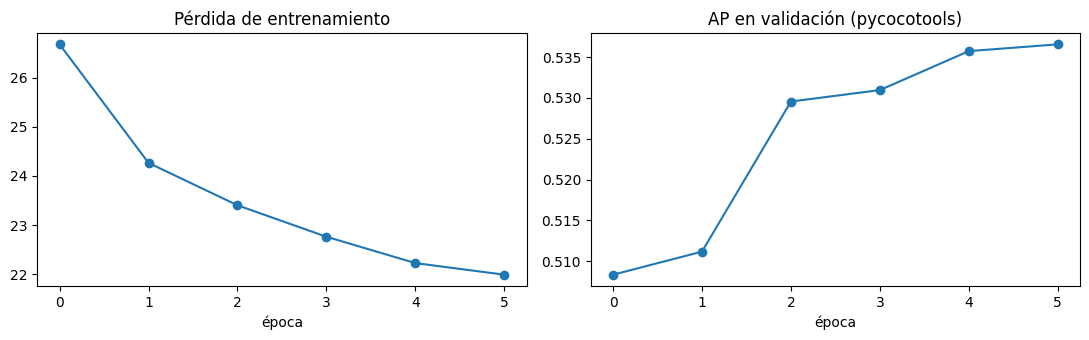

In [17]:
# Curvas de entrenamiento (desde history.csv en Drive; si no existe, desde last.pt)
try:
    import matplotlib.pyplot as plt
    hist = pd.read_csv(HIST_CSV).to_dict("records") if HIST_CSV.exists() else load_last()["history"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([h["loss"] for h in hist], marker="o"); ax[0].set_title("Pérdida de entrenamiento")
    ax[1].plot([h["val_ap"] for h in hist], marker="o"); ax[1].set_title("AP en validación (pycocotools)")
    for a in ax: a.set_xlabel("época")
    plt.tight_layout(); plt.savefig(RUN_DIR / "curvas.png", dpi=130); plt.show()
except Exception as e:
    print("Sin curvas:", type(e).__name__, e)

---
### ✅ Fin del entrenamiento

Aquí termina la parte de **entrenamiento**: los pesos quedan en `{WORK}/runs/{RUN_NAME}/best.pt` y el historial en `history.csv` (en tu Drive). Las secciones 3–5 siguientes (predicciones, evaluación con `pycocotools`, eficiencia y `resultados/A4_*.json`) se pueden ejecutar después y repetir sin reentrenar: el marcador `DONE.json` evita volver a entrenar.

## 3. Predicciones y evaluación (`pycocotools`)

Se carga `best.pt` y se predice con la inferencia de instancias oficial (top-100), máscaras binarizadas en el tamaño real de la foto. Las predicciones se guardan en formato COCO (RLE). Misma evaluación que los demás segmentadores. Se evalúa **solo** en modo agnóstico.

In [18]:
PRED_DIR = WORK / ("predicciones_pilot" if CFG["pilot"] else "predicciones"); PRED_DIR.mkdir(parents=True, exist_ok=True)
model = build_model().to(DEVICE)
model.load_state_dict(load_ckpt(CK_BEST)["model"]); model.eval()

EVAL, PRED_FILES = {}, {}
for s in ("val", "test"):
    t0 = time.time()
    infos, dets = predict_dets(model, s, limit=FINAL_LIMIT)
    ids = [im["id"] for im in infos]
    PRED_FILES[s] = str(fu.save_predictions(dets, PRED_DIR / f"{RUN_NAME}_{s}.json"))
    if CFG["agnostic"]:
        EVAL[s] = {"agnostic": fu.evaluate_segm(prep.coco(s, agnostic=True), dets, agnostic=True, img_ids=ids, n_folds=CFG["eval_folds"])}
    else:
        EVAL[s] = fu.evaluate_all(prep.coco(s), dets, img_ids=ids, per_class=(s == "test"), n_folds=CFG["eval_folds"])
    print(f"[{s}] {len(ids)} imágenes, {len(dets):,} detecciones, {time.time()-t0:.0f} s")

import pandas as pd
rows = []
for s, d in EVAL.items():
    for k, m in d.items():
        rows.append(dict(split=s, modo=k, AP=m["AP"], AP50=m["AP50"], AP75=m["AP75"], APs=m["APs"], APm=m["APm"], APl=m["APl"],
                         AR100=m["AR100"], AP_folds=f"{m.get('AP_fold_mean', float('nan')):.3f}±{m.get('AP_fold_std', float('nan')):.3f}"))
print(pd.DataFrame(rows).round(3).to_string(index=False))

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                        
-----------------------------------------------------------------------------------------------------------------------------------+------------+----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                        
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    |                                       

[val] 946 imágenes, 83,978 detecciones, 185 s
[test] 3911 imágenes, 345,919 detecciones, 760 s
split     modo    AP  AP50  AP75   APs   APm   APl  AR100    AP_folds
  val agnostic 0.559 0.775 0.598 0.005 0.135 0.608  0.713 0.561±0.026
 test agnostic 0.548 0.752 0.597 0.083 0.224 0.580  0.726 0.549±0.021


In [19]:
from collections import defaultdict
from pycocotools import mask as mu

def classification_on_matches(split, dets, ids, score_thr, iou_thr=0.5):
    """Empareja cada GT con la detección de mayor IoU (≥ iou_thr, sin mirar la clase) y compara las clases."""
    g = fu._gt_dict(prep.coco(split)); idset = set(ids)
    gd = dict(images=[im for im in g["images"] if im["id"] in idset],
              annotations=[a for a in g["annotations"] if a["image_id"] in idset], categories=g["categories"])
    gtc = fu._make_coco(gd)
    cat_ids = sorted(c["id"] for c in g["categories"]); idx = {c: i for i, c in enumerate(cat_ids)}
    nm = {c["id"]: c["name"] for c in g["categories"]}; names = [nm[c] for c in cat_ids]
    gts = defaultdict(list)
    for a in gd["annotations"]:
        if not a.get("iscrowd", 0): gts[a["image_id"]].append(a)
    dts = defaultdict(list)
    for d in dets:
        if d["image_id"] in idset and d["score"] >= score_thr: dts[d["image_id"]].append(d)
    y_true, y_pred = [], []
    n_gt = sum(len(v) for v in gts.values()); n_det = sum(len(v) for v in dts.values())
    for iid, gl in gts.items():
        dl = sorted(dts.get(iid, []), key=lambda d: -d["score"])
        if not dl: continue
        iou = np.asarray(mu.iou([d["segmentation"] for d in dl], [gtc.annToRLE(a) for a in gl], [0] * len(gl)))
        used = set()
        for i, d in enumerate(dl):
            for j in np.argsort(-iou[i]):
                if iou[i, j] < iou_thr: break
                if j in used: continue
                used.add(int(j)); y_true.append(idx[gl[j]["category_id"]]); y_pred.append(idx[d["category_id"]]); break
    out = dict(score_thr=score_thr, iou_thr=iou_thr, n_gt=n_gt, n_det=n_det, n_matched=len(y_true),
               det_recall=len(y_true) / max(n_gt, 1), det_precision=len(y_true) / max(n_det, 1))
    if y_true:
        K = len(names); P = np.zeros((len(y_true), K), dtype=np.float32); P[np.arange(len(y_true)), y_pred] = 1.0
        cm = fu.classification_metrics(y_true, P, names=names, topk=(1,))
        out.update(accuracy=cm["top1"], macro_f1=cm["macro_f1"], balanced_acc=cm["balanced_acc"],
                   per_class=cm["per_class"], top_confusions=cm["top_confusions"])
    return out


# --- Clasificación sobre las instancias detectadas (solo con clases) ---
CLS = {}
if not CFG["agnostic"]:
    SCORE_THR = 0.3 if not CFG["pilot"] else 0.05       # umbral "de uso real" (el mismo de la vista cualitativa); más bajo en el piloto
    for s in ("val", "test"):
        ids_s = [im["id"] for im in prep.images(s) if im["id"] not in BAD[s]]
        if CFG["pilot"]: ids_s = ids_s[:50]
        CLS[s] = classification_on_matches(s, fu.load_predictions(PRED_FILES[s]), ids_s, SCORE_THR)
        c = CLS[s]
        print(f"[{s}] GT {c['n_gt']:,} | detecciones (score≥{SCORE_THR}) {c['n_det']:,} | emparejadas (IoU≥0.5) {c['n_matched']:,} "
              f"| recall det. {c['det_recall']:.3f} | precisión det. {c['det_precision']:.3f}")
        if "accuracy" in c:
            print(f"      exactitud de clase {c['accuracy']:.3f} | macro-F1 {c['macro_f1']:.3f} | recall balanceado {c['balanced_acc']:.3f}")
        # resumen escalar dentro de EVAL -> se guarda en resultados/B1_*.json (sin listas largas)
        EVAL[s]["matched_cls"] = {k: v for k, v in c.items() if k not in ("per_class", "top_confusions")}
        pd.DataFrame(c.get("per_class", [])).to_csv(PRED_DIR / f"{RUN_NAME}_{s}_clasif_por_clase.csv", index=False)
        (PRED_DIR / f"{RUN_NAME}_{s}_clasif.json").write_text(json.dumps(c, indent=1, default=str))
    if CFG["pilot"]:
        print("ℹ️ Piloto: estos valores solo comprueban que el cálculo funciona.")

# Copia legible de las métricas de AP (se guarda en Drive junto a las predicciones)
pd.DataFrame(rows).round(4).to_csv(PRED_DIR / f"{RUN_NAME}_metricas.csv", index=False)
(PRED_DIR / f"{RUN_NAME}_eval.json").write_text(json.dumps(EVAL, indent=1, default=str))
print("Métricas guardadas en:", PRED_DIR)

Métricas guardadas en: /content/drive/MyDrive/calorie_counter/predicciones


## 4. Eficiencia

Latencia de **extremo a extremo**: lectura, letterbox, inferencia y posproceso (siempre se calculan los 100 candidatos y sus máscaras a resolución original), 1 imagen. Solo comparable con modelos medidos en la **misma GPU**. Se anota la precisión numérica usada.

In [20]:
sample_info = next(im for im in prep.images("val") if im["id"] not in BAD["val"])
fu.reset_gpu_peak()
LAT = fu.measure_latency(lambda: infer_one(model, sample_info), warmup=5, iters=30)
EFF = dict(params=fu.count_params(model), latency=LAT, gpu_mem_mb=fu.gpu_memory_mb(), gpu=GPU, imgsz=CFG["imgsz"], precision=AMP)
print(f"Parámetros: {EFF['params']/1e6:.1f} M | latencia: {LAT['mean_ms']:.1f} ± {LAT['std_ms']:.1f} ms (p95 {LAT['p95_ms']:.1f}) en {GPU} [{AMP}]")

Parámetros: 47.4 M | latencia: 111.3 ± 2.3 ms (p95 115.2) en NVIDIA L4 [bf16]


## 5. Guardar resultados

In [21]:
OUT_RES = WORK / ("resultados_pilot" if CFG["pilot"] else "resultados")
res_path = fu.write_result(
    RUN_NAME, model=MODEL_LABEL, metrics=EVAL, prep=prep, cfg=CFG, seed=CFG["seed"], efficiency=EFF,
    train=dict(pretrained="COCO (" + HF_NAMES[CFG["model_size"]] + ")", epochs_run=INFO.get("epochs_run"), epochs_max=CFG["epochs"],
               best_epoch=INFO.get("best_epoch"), best_val_ap=INFO.get("best_val_ap"), time_s=INFO.get("time_s"),
               batch=CFG["batch"], lr=CFG["lr"], amp=AMP, pilot=CFG["pilot"]),
    files=dict(weights=str(CK_BEST), pred_val=PRED_FILES["val"], pred_test=PRED_FILES["test"]),
    notes="Segmentador agnostico (una clase 'food')." if CFG["agnostic"] else "Segmentador con 323 clases.",
    out_dir=OUT_RES)
print("Resultado guardado en:", res_path)
if CFG["pilot"]:
    print("\n✅ PILOTO COMPLETO: el flujo funciona de extremo a extremo. Pon CFG['pilot']=False y vuelve a ejecutar todo el cuadernillo.")

Resultado guardado en: /content/drive/MyDrive/calorie_counter/resultados/A4_mask2former_swin_tiny.json


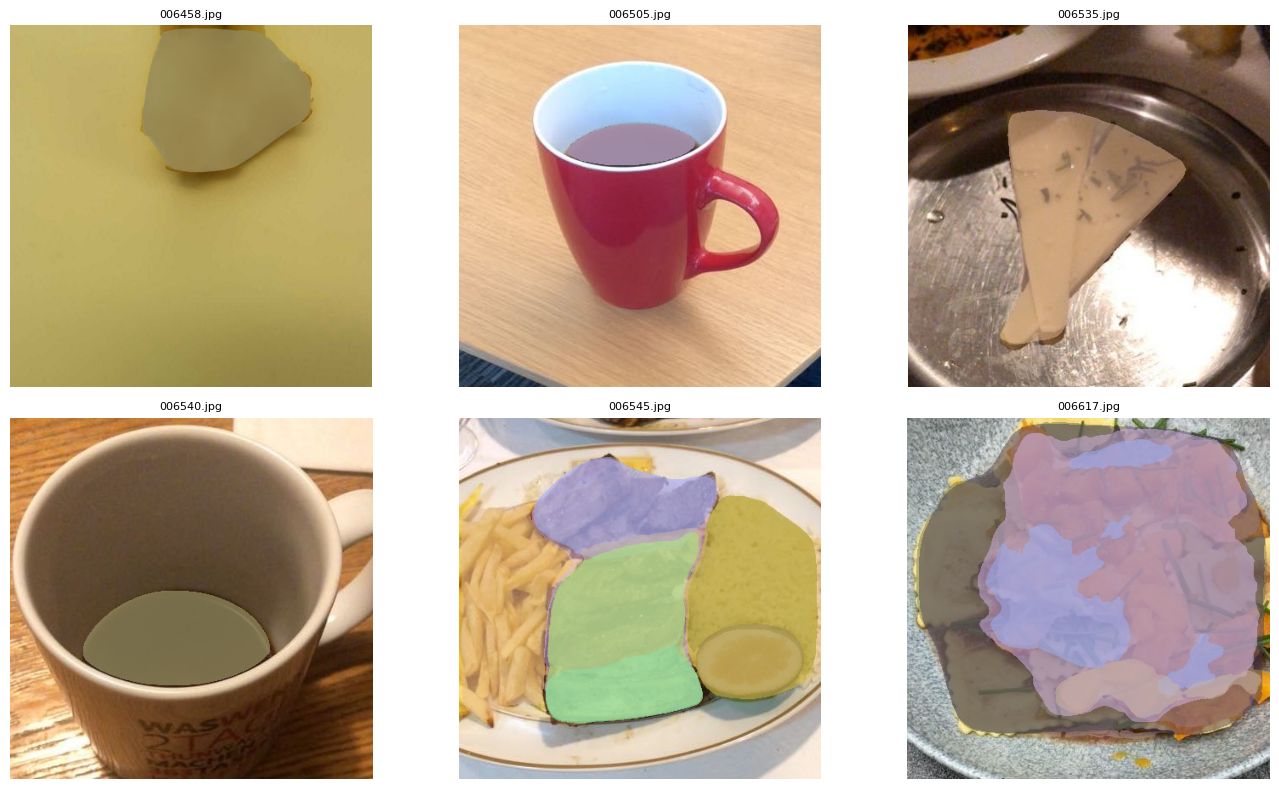

In [22]:
# Revisión cualitativa: 6 imágenes de test (puntuación >= 0.3)
try:
    import matplotlib.pyplot as plt
    rng = np.random.default_rng(0); palette = rng.integers(60, 255, (128, 3))
    tests = [im for im in prep.images("test") if im["id"] not in BAD["test"]][:6]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, im in zip(axes.flat, tests):
        img, *_ = fu.load_image_oriented(prep.image_path(im), im); arr = np.array(img).astype(float)
        sc, lb, mk = infer_one(model, im)
        for j, (m, s_) in enumerate(zip(mk.cpu().numpy(), sc.float().cpu().numpy())):
            if s_ >= 0.3: arr[m] = 0.5 * arr[m] + 0.5 * palette[j % 128]
        ax.imshow(arr.astype(np.uint8)); ax.axis("off"); ax.set_title(im["file_name"], fontsize=8)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin vista cualitativa:", type(e).__name__, e)

### Siguientes pasos
- Si el piloto salió bien: `CFG["pilot"] = False` y **Ejecutar todo**. Si Colab se desconecta, vuelve a ejecutar de arriba abajo con el mismo `CFG`: los datos se vuelven a extraer en el disco local (unos minutos) y el entrenamiento **se reanuda solo** desde `last.pt` (o `last_prev.pt`) en Drive.
- Tras A4, ejecutar **B4** con el mismo tamaño para la comparación pareada P1 vs P2.
- Dónde queda todo (en `{WORK}`): `runs/A4_mask2former_swin_*/` (pesos, `history.csv`, `curvas.png`), `predicciones/` (predicciones COCO, `_metricas.csv`, `_eval.json`) y `resultados/A4_mask2former_*.json` (lo que lee el cuadernillo 99).